# Getting Started with CDO

## Climate Data Operators (CDO)

CDO is a powerful command-line tool for manipulating and analyzing climate and forecast data. It supports NetCDF, GRIB, and other scientific data formats. This notebook introduces the basics of CDO and demonstrates how to use it from within Python.

### Learning Objectives:
- Understand what CDO is and what it can do
- Learn how to run CDO commands from Python
- Create and inspect NetCDF datasets
- Perform basic data operations with CDO

In [1]:
import os
import subprocess
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
# CDO is installed as cdo.cmd on Windows; use the right executable name.
CDO = 'cdo.cmd' if os.name == 'nt' else 'cdo'


In [2]:
# Check CDO version
result = subprocess.run([CDO, '--version'], capture_output=True, text=True)
print(result.stdout)
if result.stderr:
    print('STDERR:', result.stderr[:500])

Climate Data Operators version 2.6.0 (https://mpimet.mpg.de/cdo)
System: x86_64-w64-mingw32
CXX Compiler: g++ -D_USE_MATH_DEFINES -O2 -std=c++20 -Wno-template-body -I/mingw64/include -fopenmp -pthread
CXX version : g++.exe (Rev14, Built by MSYS2 project) 15.2.0
CXX library :
C Compiler: gcc -O2 -I/mingw64/include -fopenmp -pthread -pthread
C version : gcc.exe (Rev14, Built by MSYS2 project) 15.2.0
F77 Compiler: gfortran -g -O2
F77 version : GNU Fortran (Rev14, Built by MSYS2 project) 15.2.0
Features: 15GB 8threads c++20 OpenMP45 pthreads HDF5 NC4/HDF5 dap sz udunits2 proj fftw3 sse3
Libraries: yac/3.13.1 NetCDF/4.9.3 HDF5/2.1.1 proj/9.8.0
CDI data types: SizeType=size_t
CDI file types: srv ext ieg grb1 grb2 nc1 nc2 nc4 nc4c nc5 nczarr 
     CDI library version : 2.6.0
 cgribex library version : 2.3.1
 ecCodes library version : 2.45.0
  NetCDF library version : 4.9.3 of Dec 14 2025 17:39:55 $
    exse library version : 2.0.0
    FILE library version : 1.9.1




In [3]:
# Run cdo --help and parse the output
result = subprocess.run([CDO, '--help'], capture_output=True, text=True)
help_text = result.stdout + result.stderr

# Parse and display key sections
lines = help_text.split('\n')
print(f'Total lines of help output: {len(lines)}')
print()
print('=== OPERATOR CATEGORIES ===')
for i, line in enumerate(lines):
    line_stripped = line.strip()
    if line_stripped.startswith('-') and len(line_stripped) > 5:
        continue
    if line_stripped and not line_stripped.startswith(' '):
        print(line)
    if 'NAME' in line and 'SYNOPSIS' in help_text:
        break

Total lines of help output: 35

=== OPERATOR CATEGORIES ===
skyborn-cdo: Pre-compiled CDO (Climate Data Operators) for Python
Usage:
  skyborn-cdo --info              Show CDO binary info and version
  cdo --info                      Windows-only alias for skyborn-cdo
  cdo-win --info                  Windows-only alias for skyborn-cdo
  skyborn-cdo --help              Show this help message
  skyborn-cdo -h <operator>       Show help for a specific CDO operator
  skyborn-cdo <operator> --help   Show help for a specific CDO operator
  skyborn-cdo --operators         List all available CDO operators
  skyborn-cdo <cdo-args>          Pass arguments directly to CDO
Operator Help Examples:
  skyborn-cdo -h sellonlatbox     Show help for sellonlatbox
  skyborn-cdo -h mergetime        Show help for mergetime
  skyborn-cdo mergetime --help    Alternate operator help syntax
  skyborn-cdo -h remapbil         Show help for remapbil
Command Examples:
  skyborn-cdo -O mergetime in1.nc in2.nc out.n

## CDO Operators

CDO provides hundreds of operators organized into categories:

| Category | Description | Examples |
|---|---|---|
| **File information** | Inspect dataset metadata | `sinfo`, `ninfo`, `showlevel` |
| **Selection** | Select time steps, levels, variables | `seldate`, `sellevel`, `selname` |
| **Statistics** | Compute statistical values | `fldmean`, `timmean`, `std` |
| **Arithmetic** | Arithmetic operations on fields | `add`, `sub`, `mul`, `div` |
| **Grid transformation** | Remap to different grids | `remapbil`, `remapcon` |
| **Temporal** | Temporal aggregation | `monmean`, `yearmean`, `runmean` |

The general syntax is: `cdo [options] OPERATOR input_file output_file`

In [4]:
# Use real NCEP/DOE Reanalysis-2 monthly temperature data
import os
data_dir = '../data'
os.makedirs(data_dir, exist_ok=True)

real_file = os.path.join('..', 'datasets', 'tas_sample.nc')
ds_real = xr.open_dataset(real_file)

# Select one full year and use the variable name expected below
ds = ds_real.sel(time=slice('2000-01-01', '2000-12-31')).rename({'tas': 'temperature'})
ds['temperature'] = ds['temperature'] - 273.15  # K -> degC
ds.attrs = {
    'title': 'Real NCEP/DOE Reanalysis-2 surface air temperature',
    'source': 'NCEP/DOE AMIP-II Reanalysis (Reanalysis-2)',
}

file_path = os.path.join(data_dir, 'real_temp.nc')
ds.to_netcdf(file_path)
print(f'Using real dataset: {real_file}')
print(f'Saved working copy: {file_path}')
print(ds)

Using real dataset: ..\datasets\tas_sample.nc
Saved working copy: ../data\real_temp.nc
<xarray.Dataset> Size: 869kB
Dimensions:      (time: 12, lat: 94, lon: 192)
Coordinates:
  * time         (time) datetime64[ns] 96B 2000-01-01 2000-02-01 ... 2000-12-01
  * lat          (lat) float64 752B 88.54 86.65 84.75 ... -84.75 -86.65 -88.54
  * lon          (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 354.4 356.2 358.1
Data variables:
    temperature  (time, lat, lon) float32 866kB -27.8 -27.83 ... -26.86 -26.88
Attributes:
    title:    Real NCEP/DOE Reanalysis-2 surface air temperature
    source:   NCEP/DOE AMIP-II Reanalysis (Reanalysis-2)


In [5]:
# Use cdo sinfo to inspect the dataset
result = subprocess.run([CDO, 'sinfo', file_path], capture_output=True, text=True)
print('=== CDO sinfo output ===')
print(result.stdout)
if result.stderr:
    print('=== STDERR ===')
    print(result.stderr)

=== CDO sinfo output ===
   File format : NetCDF4
    -1 : Institut Source   T Steptype Levels Num    Points Num Dtype : Parameter ID
     1 : unknown  NCEP/DOE v instant       1   1     18048   1  F32  : -1            
   Grid coordinates :
     1 : gaussian                 : points=18048 (192x94)  F47
                              lon : 0 to 358.125 by 1.875 [degrees_east]  cyclic
                              lat : 88.542 to -88.542 [degrees_north]
   Vertical coordinates :
     1 : surface                  : levels=1
   Time coordinate :
                             time : 12 steps
     RefTime =  1980-01-01 00:00:00  Units = days  Calendar = proleptic_gregorian
  YYYY-MM-DD hh:mm:ss  YYYY-MM-DD hh:mm:ss  YYYY-MM-DD hh:mm:ss  YYYY-MM-DD hh:mm:ss
  2000-01-01 00:00:00  2000-02-01 00:00:00  2000-03-01 00:00:00  2000-04-01 00:00:00
  2000-05-01 00:00:00  2000-06-01 00:00:00  2000-07-01 00:00:00  2000-08-01 00:00:00
  2000-09-01 00:00:00  2000-10-01 00:00:00  2000-11-01 00:00:00  2000-

## Exercises

1. Use `cdo ncdump` to view the header of the real NCEP/DOE Reanalysis-2 dataset (\../datasets/tas_sample.nc\)
2. Use `cdo griddes` to get the grid description
3. Compute the global mean temperature using `cdo fldmean` and then `cdo timmean`
4. Select a single timestep using `cdo seltimestep`
5. Explore the real precipitation dataset (\../datasets/pr_sample.nc\) and inspect its variables

In [6]:
# Exercise 3: Compute global mean temperature
os.makedirs('../output', exist_ok=True)

# Step 1: Compute field mean (spatial average)
subprocess.run([CDO, 'fldmean', file_path, '../output/fldmean.nc'], capture_output=True, text=True)

# Step 2: Compute time mean (temporal average)
subprocess.run([CDO, 'timmean', '../output/fldmean.nc', '../output/global_mean_temp.nc'], capture_output=True, text=True)

# Read and display the result
ds_mean = xr.open_dataset('../output/global_mean_temp.nc')
print('Global mean temperature:')
print(ds_mean)
print(f'\nMean temperature: {ds_mean.temperature.values.ravel()[0]:.2f} degC')

Global mean temperature:
<xarray.Dataset> Size: 44B
Dimensions:      (time: 1, bnds: 2, lon: 1, lat: 1)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-06-16
  * lon          (lon) float64 8B 0.0
  * lat          (lat) float64 8B 0.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds    (time, bnds) datetime64[ns] 16B ...
    temperature  (time, lat, lon) float32 4B ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE AMIP-II Reanalysis (Reanalysis-2)
    title:        Real NCEP/DOE Reanalysis-2 surface air temperature
    history:      Sun Nov 22 18:48:37 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Mean temperature: 14.48 degC


First timestep:
<xarray.Dataset> Size: 74kB
Dimensions:      (time: 1, lon: 192, lat: 94)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-01
  * lon          (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 354.4 356.2 358.1
  * lat          (lat) float64 752B 88.54 86.65 84.75 ... -84.75 -86.65 -88.54
Data variables:
    temperature  (time, lat, lon) float32 72kB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE AMIP-II Reanalysis (Reanalysis-2)
    title:        Real NCEP/DOE Reanalysis-2 surface air temperature
    history:      Sun Nov 22 18:48:39 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...


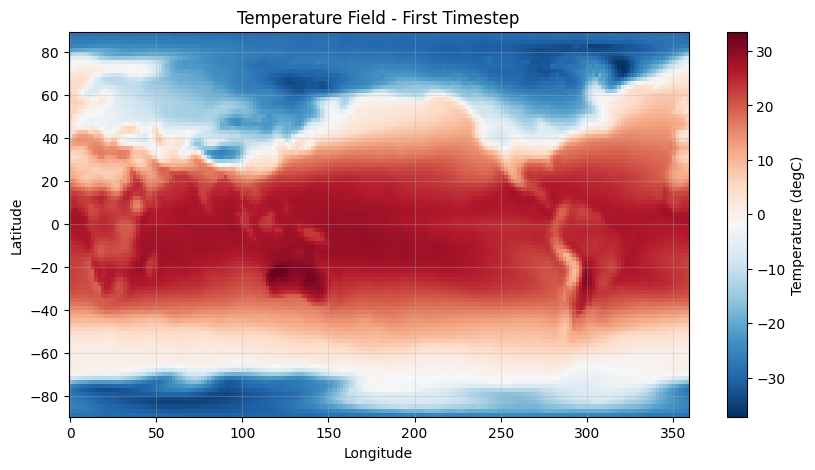

In [7]:
# Exercise 4: Select a single timestep
subprocess.run([CDO, 'seltimestep,1', file_path, '../output/timestep1.nc'], capture_output=True, text=True)

ds_ts = xr.open_dataset('../output/timestep1.nc')
print('First timestep:')
print(ds_ts)

# Quick visualization
plt.figure(figsize=(10, 5))
plt.pcolormesh(ds_ts.lon, ds_ts.lat, ds_ts.temperature[0], cmap='RdBu_r', shading='auto')
plt.colorbar(label='Temperature (degC)')
plt.title('Temperature Field - First Timestep')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(alpha=0.3)
plt.show()